# 02. Statystyki opisowe, zmienność, obsunięcia, rozkład, korelacja i beta

Notebook liczy statystyki z rozdziałów 3 do 9.2 dokumentu [`metody-statystyczne.md`](../metody-statystyczne.md), w wariantach tam wskazanych. Obliczenia są w module [`stats_methods.py`](stats_methods.py), którego poprawność na danych testowych z rozdziału 11 sprawdza notebook `03-test-data-check.ipynb`.

Wyniki są podane dla dwóch okresów:
- od 1 stycznia 2023 roku do dnia poprzedniego, czyli domyślny okres aplikacji; ten wynik zmienia się codziennie,
- okres kontrolny, cały rok 2024; dane z tego okresu już się nie zmienią, więc jego wyniki służą do porównania z aplikacją.

Analiza wydarzeń i wolumenu będzie w kolejnych notebookach.

In [1]:
import math
from datetime import date, timedelta

import matplotlib.pyplot as plt
import pandas as pd

import binance_data as bd
import stats_methods as sm

PERIOD_START = date(2023, 1, 1)
WARMUP_DAYS = 200
SYMBOLS = ["BNBUSDT", "BTCUSDT"]

data = {}
reports = {}
for symbol in SYMBOLS:
    data[symbol], reports[symbol] = bd.validate(bd.fetch_daily_klines(symbol, PERIOD_START - timedelta(days=WARMUP_DAYS)))
    r = reports[symbol]
    if r["missing_days"] or r["invalid_records"] or r["big_moves"]:
        print(f"{symbol}: brakujące={len(r['missing_days'])}, odrzucone={len(r['invalid_records'])}, zmiany >50%={len(r['big_moves'])}")
close = {symbol: frame["close"] for symbol, frame in data.items()}

if any(frame.empty for frame in data.values()):
    LAST_DAY = None
    PERIODS = {}
    print("Brak poprawnych danych do analizy.")
else:
    LAST_DAY = min(frame.index.max() for frame in data.values()).date()
    PERIODS = {
        "od 2023": (PERIOD_START, LAST_DAY),
        "rok 2024": (date(2024, 1, 1), date(2024, 12, 31)),
    }
    print(f"Dane do dnia {LAST_DAY} (UTC).")


def cut(series, period):
    return series.loc[pd.Timestamp(period[0]):pd.Timestamp(period[1])]


def pct(x):
    """Percent with two decimals and a decimal comma, as in the application."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "brak"
    return f"{x * 100:.2f}%".replace(".", ",")


def num(x, digits=4):
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "brak"
    return f"{x:.{digits}f}".replace(".", ",")

Dane do dnia 2026-11-20 (UTC).


## 1. Statystyki opisowe, zmienność, obsunięcie i kształt rozkładu

Średni zwrot, mediana, najgorszy i najlepszy dzień oraz odsetek dni wzrostowych są liczone na zwrotach prostych. Odsetek dni wzrostowych pomija dni bez zmiany ceny. Zmienność, skośność i kurtoza są liczone na zwrotach logarytmicznych. CAGR korzysta z liczby dni kalendarzowych między pierwszą a ostatnią ceną. Gdy miary nie da się policzyć, tabela pokazuje „brak”, a przyczyna jest w wierszu uwag.

In [2]:
def notes(*results):
    """Reasons for empty values and warnings, without repetitions."""
    found = []
    for result in results:
        for key, value in result.items():
            if (key.endswith("reason") or key == "warning") and value and value not in found:
                found.append(value)
    return "; ".join(found) or "brak"


def summary(prices):
    d = sm.descriptive(prices)
    v = sm.volatility(prices)
    _, dd = sm.drawdown(prices)
    s = sm.shape(prices)
    return {
        "liczba cen": d["prices"],
        "liczba zwrotów": d["returns"],
        "dni kalendarzowe": d["calendar_days"],
        "dni bez zmiany ceny": d["zero_days"],
        "średni dzienny zwrot": pct(d["mean"]),
        "mediana zwrotu": pct(d["median"]),
        "najgorszy dzień": f"{pct(d['worst'])} ({d['worst_date']})",
        "najlepszy dzień": f"{pct(d['best'])} ({d['best_date']})",
        "odsetek dni wzrostowych": pct(d["up_share"]),
        "zwrot za cały okres": pct(d["total_return"]),
        "CAGR": pct(d["cagr"]),
        "odchylenie dzienne": pct(v["daily"]),
        "zmienność roczna": pct(v["annual"]),
        "maksymalne obsunięcie": pct(dd["max_drawdown"]),
        "szczyt": dd["peak_date"],
        "dołek": dd["trough_date"],
        "dni spadku": dd["duration_days"],
        "powrót do szczytu": dd["recovery_date"] or "brak",
        "skośność": num(s["skewness"]),
        "kurtoza": num(s["kurtosis"]),
        "uwagi": notes(d, v, dd, s),
    }


pd.DataFrame({
    (period_name, symbol): summary(cut(close[symbol], period))
    for period_name, period in PERIODS.items()
    for symbol in SYMBOLS
})

od 2023                        \
                                      BNBUSDT               BTCUSDT   
liczba cen                               1420                  1420   
liczba zwrotów                           1419                  1419   
dni kalendarzowe                         1419                  1419   
dni bez zmiany ceny                         4                     0   
średni dzienny zwrot                    0,09%                 0,12%   
mediana zwrotu                          0,11%                 0,01%   
najgorszy dzień          -12,76% (2026-02-05)  -14,02% (2026-02-05)   
najlepszy dzień           17,30% (2024-03-13)   12,19% (2026-02-06)   
odsetek dni wzrostowych                52,51%                50,32%   
zwrot za cały okres                   121,29%               254,77%   
CAGR                                   22,67%                38,50%   
odchylenie dzienne                      2,64%                 2,41%   
zmienność roczna                       50,38%                46,09%   
maksymalne obsunięcie                 -58,63%               -52,97%   
szczyt                             2025-10-08            2025-10-06   
dołek                              2026-11-20            2026-06-30   
dni spadku                                408                   267   
powrót do szczytu                        brak                  brak   
skośność                               0,0706                0,2293   
kurtoza                                4,3689                3,3947   
uwagi                                    brak                  brak   

                                    rok 2024                       
                                     BNBUSDT              BTCUSDT  
liczba cen                               366                  366  
liczba zwrotów                           365                  365  
dni kalendarzowe                         365                  365  
dni bez zmiany ceny                        1                    0  
średni dzienny zwrot                   0,27%                0,24%  
mediana zwrotu                         0,13%                0,13%  
najgorszy dzień          -8,90% (2024-03-16)  -8,39% (2024-03-19)  
najlepszy dzień          17,30% (2024-03-13)  11,88% (2024-08-08)  
odsetek dni wzrostowych               52,20%               52,33%  
zwrot za cały okres                  124,02%              111,81%  
CAGR                                 124,02%              111,81%  
odchylenie dzienne                     3,01%                2,75%  
zmienność roczna                      57,46%               52,59%  
maksymalne obsunięcie                -34,73%              -26,15%  
szczyt                            2024-06-06           2024-03-13  
dołek                             2024-08-05           2024-09-06  
dni spadku                                60                  177  
powrót do szczytu                 2024-12-03           2024-11-06  
skośność                              0,5785               0,3283  
kurtoza                               3,4106               1,8055  
uwagi                                   brak                 brak

Początek 2023 roku to okolice dołka cyklu, dlatego zwrot za cały okres i CAGR dla okresu od 2023 roku są wysokie i mocno zależą od daty początkowej. Średni dzienny zwrot nie mówi, czy cena w całym okresie wzrosła; o wyniku okresu mówi zwrot za cały okres.

## 2. Wiarygodność skośności i kurtozy

Obie miary są wrażliwe na pojedyncze skrajne dni. Błąd standardowy dla rozkładu normalnego wynosi około √(6/n) dla skośności i √(24/n) dla kurtozy. Kontrolnie skośność jest liczona ponownie bez jednego, najbardziej skrajnego dnia.

In [3]:
rows = {}
for period_name, period in PERIODS.items():
    for symbol in SYMBOLS:
        s = sm.shape(cut(close[symbol], period))
        rows[(period_name, symbol)] = {
            "skośność": num(s["skewness"]),
            "błąd standardowy skośności": num(s["skewness_se"]),
            "najbardziej skrajny dzień": s["extreme_day"],
            "skośność bez tego dnia": num(s["skewness_without_extreme_day"]),
            "kurtoza": num(s["kurtosis"]),
            "błąd standardowy kurtozy": num(s["kurtosis_se"]),
        }
pd.DataFrame(rows)

od 2023                rok 2024            
                               BNBUSDT     BTCUSDT     BNBUSDT     BTCUSDT
skośność                        0,0706      0,2293      0,5785      0,3283
błąd standardowy skośności      0,0650      0,0650      0,1282      0,1282
najbardziej skrajny dzień   2024-03-13  2026-02-05  2024-03-13  2024-08-08
skośność bez tego dnia         -0,0747      0,4097      0,2502      0,1951
kurtoza                         4,3689      3,3947      3,4106      1,8055
błąd standardowy kurtozy        0,1301      0,1301      0,2564      0,2564

## 3. Zmienność krocząca

Zmienność z ostatnich 30 zwrotów, czyli 31 cen, w skali rocznej. Dzięki 200 dniom pobranym przed 2023 rokiem wykres ma wartości od pierwszego dnia okresu.

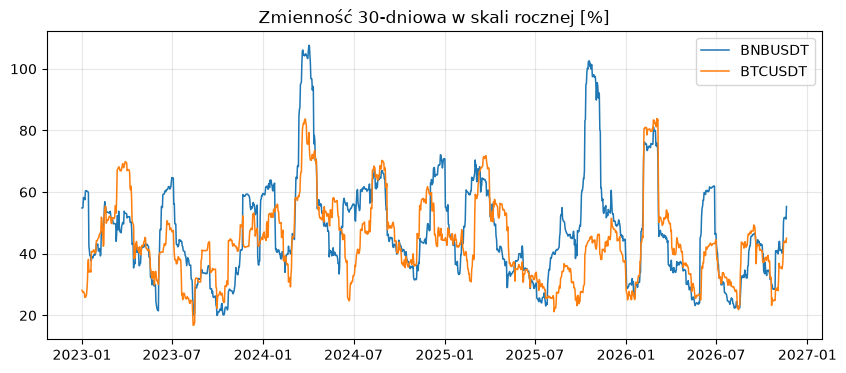

In [4]:
if "od 2023" in PERIODS:
    fig, ax = plt.subplots(figsize=(10, 4))
    for symbol in SYMBOLS:
        series = cut(sm.rolling_volatility(close[symbol], 30), PERIODS["od 2023"])
        ax.plot(series.index, series.values * 100, label=symbol, linewidth=1.1)
    ax.set_title("Zmienność 30-dniowa w skali rocznej [%]")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.show()

## 4. Średnie kroczące BNB

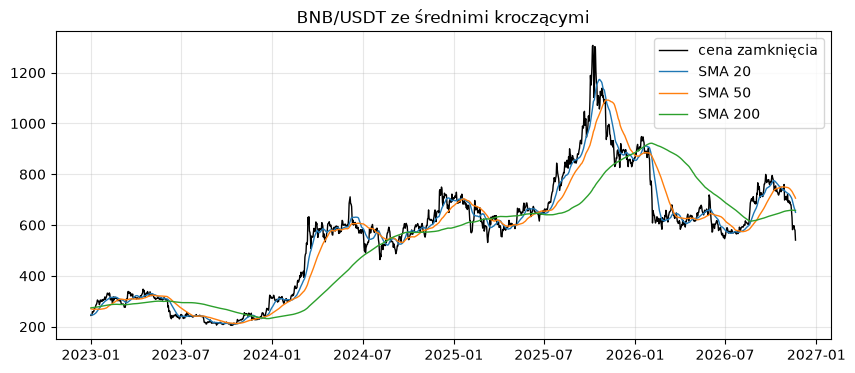

In [5]:
if "od 2023" in PERIODS:
    prices = close["BNBUSDT"]
    fig, ax = plt.subplots(figsize=(10, 4))
    period_prices = cut(prices, PERIODS["od 2023"])
    ax.plot(period_prices.index, period_prices.values, label="cena zamknięcia", linewidth=1, color="black")
    for window in (20, 50, 200):
        series = cut(sm.sma(prices, window), PERIODS["od 2023"])
        ax.plot(series.index, series.values, label=f"SMA {window}", linewidth=1)
    ax.set_title("BNB/USDT ze średnimi kroczącymi")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.show()

## 5. Obsunięcie od szczytu

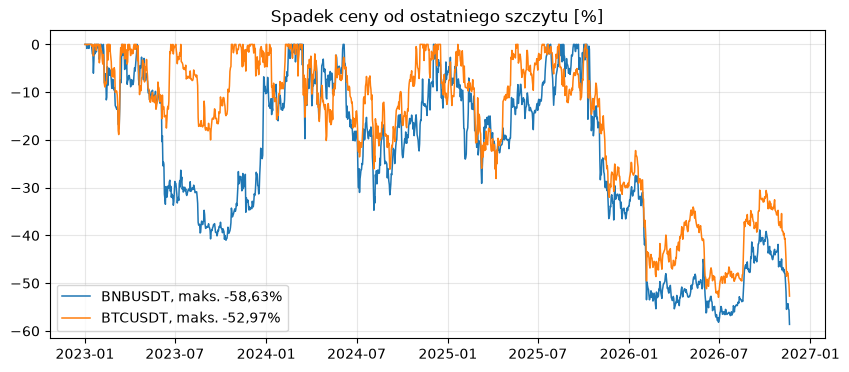

In [6]:
if "od 2023" in PERIODS:
    fig, ax = plt.subplots(figsize=(10, 4))
    for symbol in SYMBOLS:
        series, info = sm.drawdown(cut(close[symbol], PERIODS["od 2023"]))
        ax.plot(series.index, series.values * 100, label=f"{symbol}, maks. {pct(info['max_drawdown'])}", linewidth=1.1)
    ax.set_title("Spadek ceny od ostatniego szczytu [%]")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.show()

## 6. Rozkład dziennych zwrotów BNB

Histogram zwrotów logarytmicznych z regułą Freedmana-Diaconisa i krzywą rozkładu normalnego o tej samej średniej i odchyleniu. Słupki wyższe od krzywej w środku i na brzegach, a niższe pomiędzy nimi, oznaczają grube ogony, czyli dodatnią kurtozę.

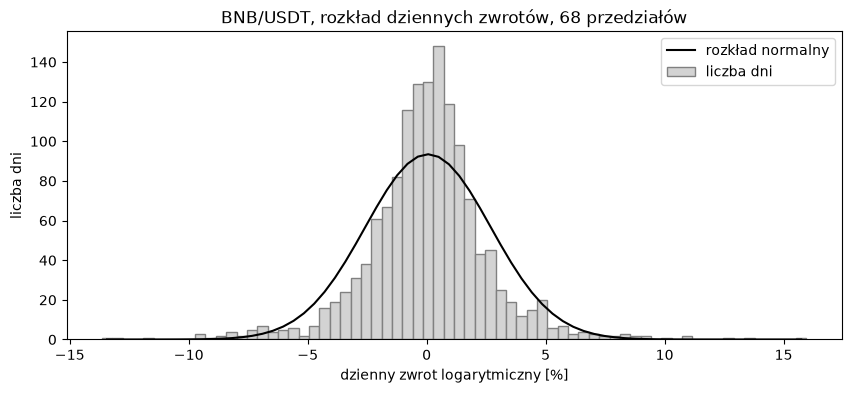

In [7]:
if "od 2023" in PERIODS:
    log_bnb = sm.returns(cut(close["BNBUSDT"], PERIODS["od 2023"]), "log")
    bins = sm.histogram(log_bnb)
    if not bins.empty:
        centers = (bins["from"] + bins["to"]) / 2
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.bar(centers * 100, bins["count"], width=(bins["to"] - bins["from"]) * 100, color="lightgray", edgecolor="gray", label="liczba dni")
        ax.plot(centers * 100, bins["normal"], color="black", label="rozkład normalny")
        ax.set_xlabel("dzienny zwrot logarytmiczny [%]")
        ax.set_ylabel("liczba dni")
        ax.set_title(f"BNB/USDT, rozkład dziennych zwrotów, {len(bins)} przedziałów")
        ax.legend()
        plt.show()

## 7. BNB na tle BTC

Korelacja Pearsona i kontrolnie Spearmana, beta, stała regresji alfa i R² na dziennych zwrotach logarytmicznych ze wspólnych dni. R² to udział wariancji zwrotów BNB wyjaśniany przez model z BTC. Pozostała część obejmuje ruch specyficzny dla BNB, ale też czynniki pominięte w modelu.

In [8]:
pd.DataFrame({
    period_name: {
        "liczba wspólnych zwrotów": m["returns"],
        "korelacja Pearsona": num(m["pearson"]),
        "korelacja Spearmana": num(m["spearman"]),
        "beta": num(m["beta"]),
        "alfa (dzienna)": num(m["alpha"], 6),
        "R²": num(m["r_squared"]),
        "część niewyjaśniona przez model z BTC, 1 − R²": pct(1 - m["r_squared"]),
        "uwagi": notes(m),
    }
    for period_name, period in PERIODS.items()
    for m in [sm.market_relation(cut(close["BNBUSDT"], period), cut(close["BTCUSDT"], period))]
})

,od 2023,rok 2024
liczba wspólnych zwrotów,1419,365
korelacja Pearsona,"0,6821","0,6419"
korelacja Spearmana,"0,7043","0,6664"
beta,"0,7456","0,7014"
alfa (dzienna),"-0,000106","0,000768"
R²,"0,4652","0,4121"
"część niewyjaśniona przez model z BTC, 1 − R²","53,48%","58,79%"
uwagi,brak,brak


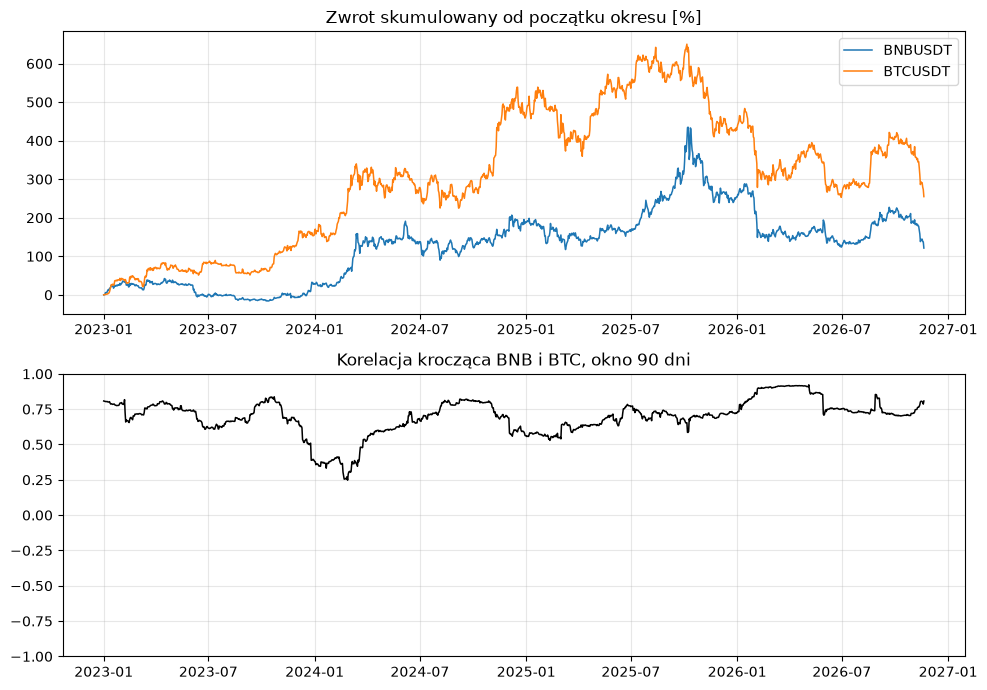

In [9]:
if "od 2023" in PERIODS:
    fig, axes = plt.subplots(2, 1, figsize=(10, 7))
    period = PERIODS["od 2023"]
    bnb_p = cut(close["BNBUSDT"], period)
    btc_p = cut(close["BTCUSDT"], period)
    common = bnb_p.index.intersection(btc_p.index).sort_values()
    if len(common):
        for symbol, series in [("BNBUSDT", bnb_p.loc[common]), ("BTCUSDT", btc_p.loc[common])]:
            axes[0].plot(series.index, (series / series.iloc[0] - 1) * 100, label=symbol, linewidth=1.1)
    axes[0].set_title("Zwrot skumulowany od początku okresu [%]")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    rolling = cut(sm.rolling_correlation(close["BNBUSDT"], close["BTCUSDT"], 90), period)
    axes[1].plot(rolling.index, rolling.values, color="black", linewidth=1.1)
    axes[1].set_ylim(-1, 1)
    axes[1].set_title("Korelacja krocząca BNB i BTC, okno 90 dni")
    axes[1].grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

## 8. Wartości kontrolne dla aplikacji

Wyniki dla roku 2024 z dokładnością do 10 miejsc po przecinku, jako ułamki. Aplikacja liczona na tych samych danych powinna je odtworzyć do szóstej cyfry znaczącej, zgodnie z rozdziałem 9 dokumentu wymagań.

In [10]:
if "rok 2024" in PERIODS:
    period = PERIODS["rok 2024"]
    bnb = cut(close["BNBUSDT"], period)
    btc = cut(close["BTCUSDT"], period)
    d = sm.descriptive(bnb)
    v = sm.volatility(bnb)
    _, dd = sm.drawdown(bnb)
    s = sm.shape(bnb)
    m = sm.market_relation(bnb, btc)
    control = {
        "liczba cen BNB": d["prices"],
        "liczba zwrotów BNB": d["returns"],
        "dni kalendarzowe": d["calendar_days"],
        "dni bez zmiany ceny": d["zero_days"],
        "średni dzienny zwrot prosty": d["mean"],
        "mediana zwrotu prostego": d["median"],
        "najgorszy dzień": (d["worst"], str(d["worst_date"])),
        "najlepszy dzień": (d["best"], str(d["best_date"])),
        "odsetek dni wzrostowych": d["up_share"],
        "zwrot za okres": d["total_return"],
        "CAGR": d["cagr"],
        "odchylenie dzienne, zwroty log.": v["daily"],
        "zmienność roczna": v["annual"],
        "maksymalne obsunięcie": (dd["max_drawdown"], str(dd["peak_date"]), str(dd["trough_date"])),
        "skośność G1": s["skewness"],
        "kurtoza G2": s["kurtosis"],
        "korelacja Pearsona z BTC": m["pearson"],
        "korelacja Spearmana z BTC": m["spearman"],
        "beta": m["beta"],
        "R²": m["r_squared"],
    }
    for name, value in control.items():
        if isinstance(value, tuple):
            print(f"{name}: {value[0]:.10f}, " + ", ".join(value[1:]))
        elif isinstance(value, float):
            print(f"{name}: {value:.10f}")
        else:
            print(f"{name}: {value}")

liczba cen BNB: 366
liczba zwrotów BNB: 365
dni kalendarzowe: 365
dni bez zmiany ceny: 1
średni dzienny zwrot prosty: 0.0026669881
mediana zwrotu prostego: 0.0012847376
najgorszy dzień: -0.0889837206, 2024-03-16
najlepszy dzień: 0.1730232558, 2024-03-13
odsetek dni wzrostowych: 0.5219780220
zwrot za okres: 1.2401913876
CAGR: 1.2401913876
odchylenie dzienne, zwroty log.: 0.0300733644
zmienność roczna: 0.5745508210
maksymalne obsunięcie: -0.3473003375, 2024-06-06, 2024-08-05
skośność G1: 0.5785304989
kurtoza G2: 3.4106287003
korelacja Pearsona z BTC: 0.6419458658
korelacja Spearmana z BTC: 0.6664069331
beta: 0.7013956405
R²: 0.4120944946
